# 05 — Evidence dashboard

**Final output.** Reads only from `data/marts/` — the published metrics, not the
raw data. Nothing here recomputes a metric, which is the point: if this notebook
and the pipeline disagreed, the pipeline would be wrong.

Regenerate the markdown version with `python -m pipeline.report`.

In [3]:
import sys, json, duckdb, pandas as pd
sys.path.insert(0, '../src')
from pipeline.config import load_config
cfg = load_config('../config/pipeline.yaml')
con = duckdb.connect()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
RAW, MARTS, STG = '../data/raw', '../data/marts', '../data/staging'

import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.grid': True,
                     'grid.alpha': 0.3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
INK, WARN = '#2c3e50', '#c0392b'

## The KPI: congested trip rate by month

,month,trips,congested,kpi_pct,avg_speed_mph
0,2024-01,2915737.0,917599.0,31.47,11.45
1,2024-02,2950680.0,993132.0,33.66,11.10
2,2024-03,3502288.0,1159929.0,33.12,11.12
3,2024-04,3473877.0,1202497.0,34.62,11.04
4,2024-05,3680008.0,1393812.0,37.88,10.59
5,2024-06,3487222.0,1222560.0,35.06,10.84


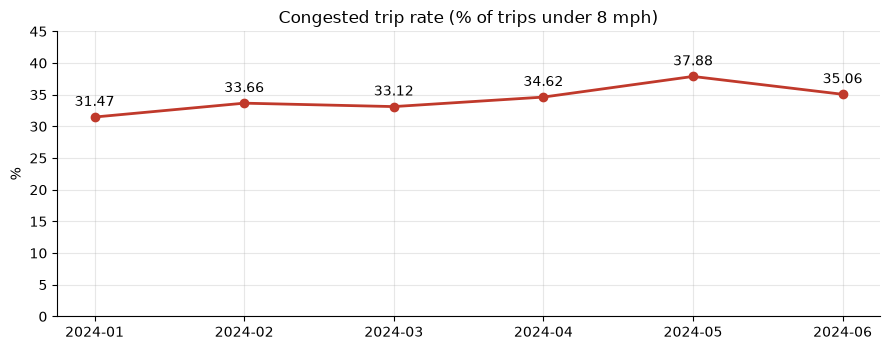

In [4]:
kpi = con.sql(f'''
    SELECT month, sum(trips) AS trips, sum(congested_trips) AS congested,
           round(100.0*sum(congested_trips)/sum(trips), 2) AS kpi_pct,
           round(sum(avg_speed_mph*trips)/sum(trips), 2)   AS avg_speed_mph
    FROM read_parquet('{MARTS}/m_congested_rate/**/*.parquet')
    GROUP BY month ORDER BY month
''').df()
display(kpi)
fig, ax = plt.subplots()
ax.plot(kpi.month, kpi.kpi_pct, marker='o', color=WARN, lw=2)
ax.set_title('Congested trip rate (% of trips under 8 mph)')
ax.set_ylabel('%'); ax.set_ylim(0, 45)
for x, y in zip(kpi.month, kpi.kpi_pct): ax.annotate(f'{y}', (x, y), textcoords='offset points', xytext=(0, 8), ha='center')
plt.tight_layout(); plt.show()

Congestion rose **6.4 points** from January to its May peak — but see L4: six months cannot separate trend from season.

## Where: by borough

,borough,trips,kpi_pct,avg_speed_mph
0,Manhattan,17904014.0,37.71,9.93
1,Brooklyn,277960.0,28.05,11.78
2,Bronx,55460.0,21.16,13.45
3,Queens,1771736.0,2.77,21.71


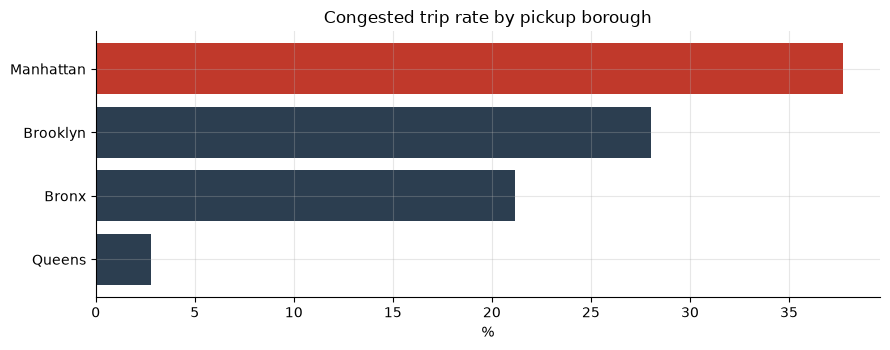

In [5]:
b = con.sql(f'''
    SELECT borough, sum(trips) AS trips,
           round(100.0*sum(congested_trips)/sum(trips), 2) AS kpi_pct,
           round(sum(avg_speed_mph*trips)/sum(trips), 2) AS avg_speed_mph
    FROM read_parquet('{MARTS}/m_congested_rate/**/*.parquet')
    GROUP BY borough HAVING sum(trips) > 10000 ORDER BY kpi_pct DESC
''').df()
display(b)
fig, ax = plt.subplots()
ax.barh(b.borough, b.kpi_pct, color=[WARN if v > 30 else INK for v in b.kpi_pct])
ax.set_title('Congested trip rate by pickup borough'); ax.set_xlabel('%')
ax.invert_yaxis(); plt.tight_layout(); plt.show()

Queens looks excellent at 2.8% — but that is an **airport artefact**, not free-flowing
streets. Airport runs are highway trips and dominate Queens pickups. This is exactly
the kind of composition effect a borough average hides, which is why M3 exists.

## When: the headline operational finding

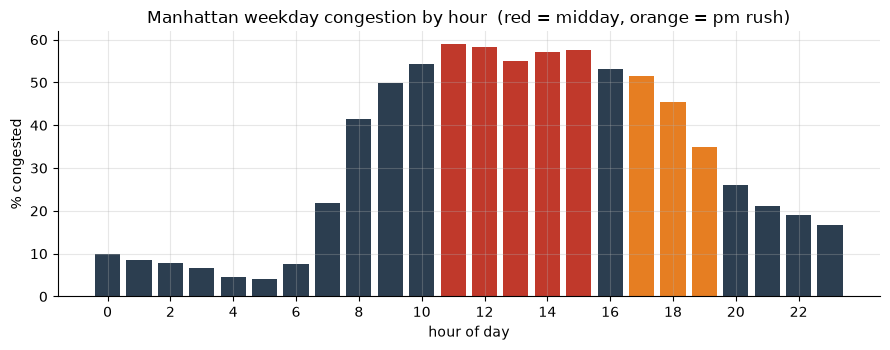

midday 11-15 : 57.4%
pm rush 17-19: 44.0%
midday is 13.4 points WORSE than the evening peak


In [6]:
h = con.sql(f'''
    SELECT pickup_hour, round(100.0*sum(congested_trips)/sum(trips), 1) AS kpi_pct
    FROM read_parquet('{MARTS}/m_congested_rate/**/*.parquet')
    WHERE borough = 'Manhattan' AND NOT is_weekend
    GROUP BY pickup_hour ORDER BY pickup_hour
''').df()
fig, ax = plt.subplots()
colors = [WARN if 11 <= x <= 15 else ('#e67e22' if 17 <= x <= 19 else INK) for x in h.pickup_hour]
ax.bar(h.pickup_hour, h.kpi_pct, color=colors)
ax.set_title('Manhattan weekday congestion by hour  (red = midday, orange = pm rush)')
ax.set_xlabel('hour of day'); ax.set_ylabel('% congested'); ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

mid = h[(h.pickup_hour >= 11) & (h.pickup_hour <= 15)].kpi_pct.mean()
pm  = h[(h.pickup_hour >= 17) & (h.pickup_hour <= 19)].kpi_pct.mean()
print(f"midday 11-15 : {mid:.1f}%")
print(f"pm rush 17-19: {pm:.1f}%")
print(f"midday is {mid - pm:.1f} points WORSE than the evening peak")

**Midday, not rush hour.** Weekday 11:00–15:00 runs ~13 points worse than the
17:00–19:00 peak. This is the most actionable output of the project: it points curb
and loading-zone enforcement at the middle of the day, which is not where an
intuition-led programme would aim first.

## Airport segment

In [7]:
a = con.sql(f'''
    SELECT CASE WHEN is_airport_trip THEN 'Airport' ELSE 'Non-airport' END AS segment,
           sum(trips) AS trips,
           round(sum(median_duration_min*trips)/sum(trips), 1) AS med_duration_min,
           round(sum(avg_speed_mph*trips)/sum(trips), 2) AS avg_speed_mph,
           round(sum(congested_rate_pct*trips)/sum(trips), 2) AS kpi_pct
    FROM read_parquet('{MARTS}/m_airport/**/*.parquet') GROUP BY 1
''').df()
display(a)

,segment,trips,med_duration_min,avg_speed_mph,kpi_pct
0,Non-airport,18243058.0,11.7,9.79,37.93
1,Airport,1953414.0,35.6,23.09,0.50


## Weather effect

In [8]:
w = con.sql(f'''
    SELECT CASE WHEN is_wet_hour THEN 'Wet' ELSE 'Dry' END AS condition,
           sum(trips) AS trips,
           round(sum(avg_speed_mph*trips)/sum(trips), 2) AS avg_speed_mph,
           round(sum(congested_rate_pct*trips)/sum(trips), 2) AS kpi_pct
    FROM read_parquet('{MARTS}/m_weather_effect/**/*.parquet') GROUP BY 1 ORDER BY 1
''').df()
display(w)
drop = 100*(1 - w[w.condition=='Wet'].avg_speed_mph.iat[0]/w[w.condition=='Dry'].avg_speed_mph.iat[0])
print(f"Rain costs {drop:.1f}% of network speed and adds "
      f"{w[w.condition=='Wet'].kpi_pct.iat[0] - w[w.condition=='Dry'].kpi_pct.iat[0]:.1f} points to the KPI.")
print("Real - but far smaller than the midday effect. Congestion here is mostly structural.")

,condition,trips,avg_speed_mph,kpi_pct
0,Dry,16555476.0,11.19,33.41
1,Wet,3640996.0,10.55,38.38


Rain costs 5.7% of network speed and adds 5.0 points to the KPI.
Real - but far smaller than the midday effect. Congestion here is mostly structural.


## Trust: what was excluded, and why

In [9]:
dq = con.sql(f'''
    SELECT rule_id, action, sum(hits) AS hits,
           round(100.0*sum(hits)/sum(total_trips), 3) AS pct_of_trips
    FROM read_parquet('{MARTS}/m_data_quality/**/*.parquet')
    GROUP BY rule_id, action ORDER BY pct_of_trips DESC
''').df()
display(dq)
print(f"Excluded from speed metrics: {dq[dq.action=='exclude_core'].pct_of_trips.sum():.2f}% of trips")
print("V08 is flag-only - it excludes nothing. Its rate doubled in March 2024 (see K7).")

,rule_id,action,hits,pct_of_trips
0,V08_missing_passenger_count,flag_only,2214430.0,10.712
1,V03_distance_out_of_range,exclude_core,382955.0,1.853
2,V02_duration_out_of_range,exclude_core,259976.0,1.258
3,V07_negative_total,exclude_fare,258613.0,1.251
4,V06_unknown_zone,exclude_zone,212900.0,1.030
5,V04_implausible_speed,exclude_core,7772.0,0.038
6,V01_dropoff_before_pickup,exclude_core,6512.0,0.032
7,V05_pickup_outside_month,exclude_core,193.0,0.001


Excluded from speed metrics: 3.18% of trips
V08 is flag-only - it excludes nothing. Its rate doubled in March 2024 (see K7).


---

## Known / Unknown / Assumption / Limitation

Full version: [`docs/known_unknowns.md`](../docs/known_unknowns.md).

**KNOWN** — Manhattan midday is the worst segment (57.3% vs 44.3% pm peak);
congestion rose 6.4pp Jan→May; Queens' good score is an airport artefact; rain adds
~5pp; data quality broke in March (V08 doubled).

**UNKNOWN** — unmet demand (only completed trips are recorded, so a zone nobody
serves looks healthy); the cause of any individual delay; ride-hail traffic;
whether any past intervention worked.

**ASSUMPTION** — average speed proxies congestion; 8 mph is a meaningful line;
`trip_distance` is real; Central Park represents all boroughs; zero duplicates
continue (monitored, not guaranteed).

**LIMITATION** — the absolute level is threshold-dependent (14.7% at 6 mph → 55.0%
at 10 mph) though the **ranking is stable**; taxis are a biased sample; one DST day
is misaligned; six months cannot separate trend from season; a ~2-month lag makes
this a planning instrument, not a monitor.

## The decision this supports

**Rank zones and hours for curb, signal and dispatch intervention, then measure
month over month whether the intervention moved the number.**

Use for **ranking and trend**. Do not quote the absolute percentage.